# Graph Data Science - Midterm Examination (UTS)
### Daffa Ahmad Pangreksa - 24031554159 - 24INT
**Folds Configuration:**
- Training Period (P1): 2015-07-01 to 2015-07-10 (10 days)
- Testing Period (P2): 2015-07-11 to 2015-07-18 (8 days)


In [1]:
import sys
import os
import subprocess
import time
import zipfile
import socket
import getpass

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run(["pip", "install", "-q", "neo4j", "pandas", "numpy", "scipy", "scikit-learn", "networkx", "matplotlib", "tqdm", "openpyxl"], check=True)

import pandas as pd
import numpy as np
import scipy.sparse as sp
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase, RoutingControl

### Neo4j Setup
Starts a local Neo4j Community server when running on Google Colab.

In [2]:
if IN_COLAB:
    java_check = subprocess.run(["which", "java"], capture_output=True, text=True)
    if not java_check.stdout.strip():
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jre-headless"], check=True)
        os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

    if not os.path.exists("neo4j"):
        print("Downloading Neo4j Community Server for Google Colab...")
        subprocess.run(["wget", "-q", "https://neo4j.com/artifact.php?name=neo4j-community-5.15.0-unix.tar.gz", "-O", "neo4j.tar.gz"], check=True)
        subprocess.run(["tar", "-xzf", "neo4j.tar.gz"], check=True)
        subprocess.run(["mv", "neo4j-community-5.15.0", "neo4j"], check=True)

        with open("neo4j/conf/neo4j.conf", "a") as f:
            f.write("\nserver.default_listen_address=0.0.0.0\n")
            f.write("server.bolt.listen_address=0.0.0.0:7687\n")

        subprocess.run(["neo4j/bin/neo4j-admin", "dbms", "set-initial-password", "password"], check=True)
        subprocess.run(["neo4j/bin/neo4j", "start"], check=True)
    else:
        status_check = subprocess.run(["neo4j/bin/neo4j", "status"], capture_output=True, text=True)
        if "is running" not in status_check.stdout:
            subprocess.run(["neo4j/bin/neo4j", "start"], check=True)

    print("Waiting for Neo4j service to initialize on port 7687...")
    port_ready = False
    start_time = time.time()
    while time.time() - start_time < 45:
        try:
            with socket.create_connection(("127.0.0.1", 7687), timeout=2):
                port_ready = True
                break
        except (ConnectionRefusedError, OSError):
            time.sleep(2)

    if port_ready:
        print("Neo4j is successfully running and accepting connections!")
    else:
        print("Warning: Port 7687 timed out. Displaying last 30 log lines:")
        if os.path.exists("neo4j/logs/neo4j.log"):
            with open("neo4j/logs/neo4j.log", "r") as log_f:
                lines = log_f.readlines()
                print("".join(lines[-30:]))

Waiting for Neo4j service to initialize on port 7687...
Neo4j is successfully running and accepting connections!


## 1. Tugas Pendahuluan - Checkpoint 1.2

1. **Database name.** `neo4j`, the default user database. Every query passes `database_="neo4j"`. The `system` database is only used for administration.
2. **Accessing other databases in one instance.**
   - Cypher: `USE custom_db MATCH (n) RETURN count(n);`
   - Python: `driver.session(database="custom_db")` or `execute_query(..., database_="custom_db")`
   - Admin commands on `system`: `SHOW DATABASES`, `CREATE DATABASE`, `START` / `STOP` / `DROP DATABASE`
   - Composite databases: `USE composite.graphAlias`

   Multiple user databases need Enterprise Edition. The Community Edition used here on Colab only has `neo4j` and `system`.
3. **Graph type.** A directed property graph with one node label (`Person`) and one relationship type (`KNOWS`). The edge `(a)-[:KNOWS]->(friend)` has a direction, so Arthur knowing Guinevere does not mean the reverse. `MERGE` prevents duplicate nodes and edges.

In [3]:
if IN_COLAB:
    URI = "bolt://127.0.0.1:7687"
else:
    URI = os.getenv("NEO4J_URI", "neo4j://localhost:7687")

neo_user = os.getenv("NEO4J_USER", "neo4j")
neo_pass = os.getenv("NEO4J_PASSWORD") or getpass.getpass("Enter Neo4j password: ")
AUTH = (neo_user, neo_pass)

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Connected to Neo4j successfully!")

Enter Neo4j password: ··········
Connected to Neo4j successfully!


### Database Reset
Clears the database with `MATCH (n) DETACH DELETE n` so every run starts clean.

In [4]:
with driver.session(database="neo4j") as session:
    session.run("MATCH (n) DETACH DELETE n")

## 2.1 Wrangling and EDA

### Question 1: Time Periods
- **P1 (train):** 2015-07-01 to 2015-07-10 UTC (10 days)
- **P2 (test):** 2015-07-11 to 2015-07-18 UTC (8 days)

The windows are back to back and do not overlap, and P2 comes after P1, so there is no leakage from the future. Both have enough data: P1 has 214,725 events (114,687 visitors, 67,926 items) and P2 has 177,360 events (107,053 visitors, 59,890 items). They are kept short so everything fits in local Neo4j and memory, at the cost of very short user histories.

### Question 2: Timestamp Filter and CSV Export
`timestamp` is Unix epoch in milliseconds. It is converted to UTC, split into P1 and P2, and saved as CSV files.

In [5]:
data_candidates = ["events.csv", os.path.join("data", "events.csv"), "/content/events.csv"]
found_path = None
for candidate in data_candidates:
    if os.path.exists(candidate):
        found_path = candidate
        break

if found_path is None:
    if IN_COLAB:
        print("events.csv not found. Downloading dataset...")
        subprocess.run(["curl", "-L", "-o", "ecommerce-dataset.zip", "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"], check=True)
        with zipfile.ZipFile("ecommerce-dataset.zip", "r") as z:
            z.extractall(".")
        found_path = "events.csv"
    else:
        raise FileNotFoundError("events.csv not found. Please place events.csv in the working directory.")

df_raw = pd.read_csv(found_path)
df_raw["datetime"] = pd.to_datetime(df_raw["timestamp"], unit="ms", utc=True)

p1_start = pd.Timestamp("2015-07-01 00:00:00", tz="UTC")
p1_end = pd.Timestamp("2015-07-10 23:59:59.999", tz="UTC")
p2_start = pd.Timestamp("2015-07-11 00:00:00", tz="UTC")
p2_end = pd.Timestamp("2015-07-18 23:59:59.999", tz="UTC")

df_p1 = df_raw[(df_raw["datetime"] >= p1_start) & (df_raw["datetime"] <= p1_end)].copy()
df_p2 = df_raw[(df_raw["datetime"] >= p2_start) & (df_raw["datetime"] <= p2_end)].copy()

df_p1["fold"] = "P1_train"
df_p2["fold"] = "P2_test"
df_combined_filtered = pd.concat([df_p1, df_p2], ignore_index=True)

df_p1.to_csv("events_p1_train.csv", index=False)
df_p2.to_csv("events_p2_test.csv", index=False)
df_combined_filtered.to_csv("events_filtered_p1_p2.csv", index=False)

summary_stats = pd.DataFrame({
    "Fold": ["P1 (Training)", "P2 (Testing)"],
    "Start Date": [p1_start.strftime("%Y-%m-%d"), p2_start.strftime("%Y-%m-%d")],
    "End Date": [p1_end.strftime("%Y-%m-%d"), p2_end.strftime("%Y-%m-%d")],
    "Total Rows": [len(df_p1), len(df_p2)],
    "Unique Visitors": [df_p1["visitorid"].nunique(), df_p2["visitorid"].nunique()],
    "Unique Items": [df_p1["itemid"].nunique(), df_p2["itemid"].nunique()]
})
summary_stats.to_csv("summary_stats_p1_p2.csv", index=False)
display(summary_stats)

events.csv not found. Downloading dataset...


,Fold,Start Date,End Date,Total Rows,Unique Visitors,Unique Items
0,P1 (Training),2015-07-01,2015-07-10,214725,114687,67926
1,P2 (Testing),2015-07-11,2015-07-18,177360,107053,59890


### Ingesting P1 into Neo4j
Uniqueness constraints on `Visitor.visitorId` and `Item.itemId` come first. Rows are then sent in batches of 5,000 with `UNWIND`. `MERGE` creates each visitor and item once, and a `CALL` subquery adds one `VIEWED`, `ADDED_TO_CART` or `BOUGHT` relationship per row. The cell skips ingestion if relationships already exist, so run the reset cell first to re-ingest.

In [6]:
with driver.session(database="neo4j") as session:
    session.run("CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id_unique IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
    existing_rels = session.run("MATCH ()-[r]->() RETURN count(r) AS c").single()["c"]

if existing_rels > 0:
    print(f"Ingestion skipped: database already contains {existing_rels} relationships. Run the reset cell first to re-ingest.")
else:
    batch_size = 5000
    ingest_cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
    p1_records = df_p1[ingest_cols].to_dict(orient="records")
    for rec in p1_records:
        rec["transactionid"] = None if pd.isna(rec["transactionid"]) else int(rec["transactionid"])

    ingest_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """

    with driver.session(database="neo4j") as session:
        for start_idx in range(0, len(p1_records), batch_size):
            session.run(ingest_query, batch=p1_records[start_idx:start_idx + batch_size])

    print(f"Ingested {len(p1_records)} P1 events in {-(-len(p1_records) // batch_size)} batches.")

Ingested 214725 P1 events in 43 batches.


### Question 3: Subgraph Composition

Nodes per type:

```cypher
MATCH (n)
RETURN labels(n)[0] AS node_type, count(n) AS node_count
ORDER BY node_count DESC
```

`labels(n)[0]` gives the node's label and `count(n)` counts nodes per label.

Relationships per type:

```cypher
MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(r) AS relationship_count
ORDER BY relationship_count DESC
```

`type(r)` gives the relationship type and `count(r)` counts each one. Both queries run with `session.run()` and are loaded into DataFrames.

In [7]:
with driver.session(database="neo4j") as session:
    nodes_res = session.run("MATCH (n) RETURN labels(n)[0] AS node_type, count(n) AS node_count ORDER BY node_count DESC")
    df_nodes = pd.DataFrame([dict(record) for record in nodes_res])

    rels_res = session.run("MATCH ()-[r]->() RETURN type(r) AS relationship_type, count(r) AS relationship_count ORDER BY relationship_count DESC")
    df_rels = pd.DataFrame([dict(record) for record in rels_res])

display(df_nodes)
display(df_rels)

df_nodes.to_csv("subgraph_nodes_composition.csv", index=False)
df_rels.to_csv("subgraph_relationships_composition.csv", index=False)

,node_type,node_count
0,Visitor,114687
1,Item,67926


,relationship_type,relationship_count
0,VIEWED,207368
1,ADDED_TO_CART,5520
2,BOUGHT,1837


The P1 subgraph has 114,687 visitors and 67,926 items, matching the unique ids in P1. The relationships add up to 207,368 + 5,520 + 1,837 = 214,725, exactly the number of P1 rows, so each event became one relationship.

### Question 4: Vector Space Modeling (VSM) for Users


User VSM Dimensions (Items): 67926
User VSM Matrix Shape (|U| x |I|): (114687, 67926)
User VSM Matrix Sparsity: 99.9978%


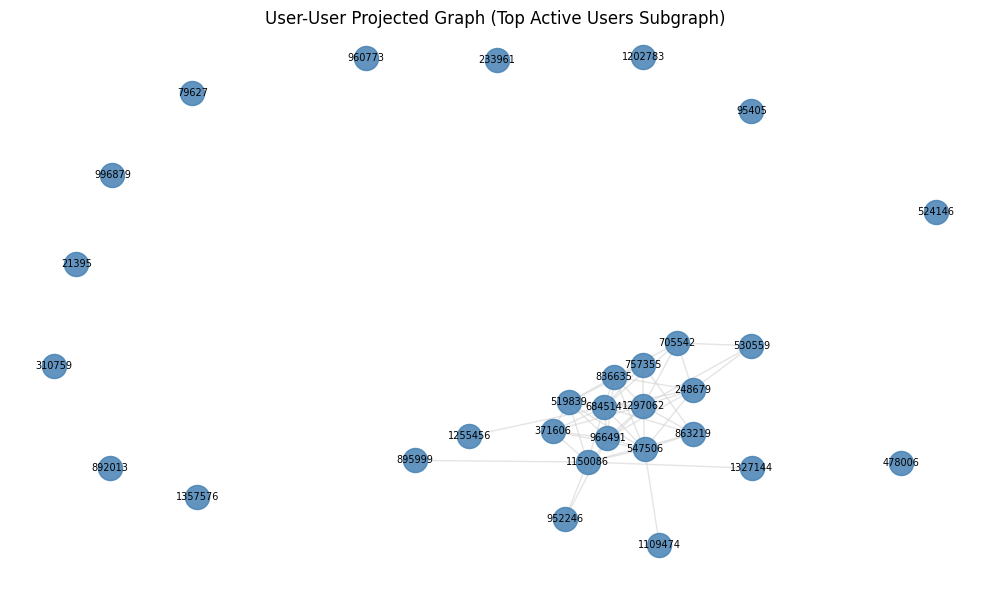

In [8]:
event_weights = {"view": 1, "addtocart": 2, "transaction": 3}
df_p1_vsm = df_p1.copy()
df_p1_vsm["weight"] = df_p1_vsm["event"].map(event_weights)
df_p1_vsm_grouped = df_p1_vsm.groupby(["visitorid", "itemid"])["weight"].sum().reset_index()

unique_users = np.sort(df_p1_vsm_grouped["visitorid"].unique())
unique_items = np.sort(df_p1_vsm_grouped["itemid"].unique())

user_to_idx = {uid: idx for idx, uid in enumerate(unique_users)}
item_to_idx = {iid: idx for idx, iid in enumerate(unique_items)}

row_indices = df_p1_vsm_grouped["visitorid"].map(user_to_idx).values
col_indices = df_p1_vsm_grouped["itemid"].map(item_to_idx).values
values = df_p1_vsm_grouped["weight"].values

user_item_matrix = sp.csr_matrix((values, (row_indices, col_indices)), shape=(len(unique_users), len(unique_items)))

total_cells = user_item_matrix.shape[0] * user_item_matrix.shape[1]
nonzero_cells = user_item_matrix.nnz
user_sparsity = 1.0 - (nonzero_cells / total_cells)

print("User VSM Dimensions (Items):", user_item_matrix.shape[1])
print("User VSM Matrix Shape (|U| x |I|):", user_item_matrix.shape)
print("User VSM Matrix Sparsity:", f"{user_sparsity * 100:.4f}%")

top_active_users_idx = np.argsort(np.diff(user_item_matrix.indptr))[-30:]
sub_user_matrix = user_item_matrix[top_active_users_idx]
user_sim_sub = cosine_similarity(sub_user_matrix)
np.fill_diagonal(user_sim_sub, 0)

G_user = nx.Graph()
for i, u_idx in enumerate(top_active_users_idx):
    G_user.add_node(unique_users[u_idx])
    for j in range(i + 1, len(top_active_users_idx)):
        if user_sim_sub[i, j] > 0.05:
            G_user.add_edge(unique_users[u_idx], unique_users[top_active_users_idx[j]], weight=user_sim_sub[i, j])

plt.figure(figsize=(10, 6))
pos_u = nx.spring_layout(G_user, seed=42)
nx.draw_networkx_nodes(G_user, pos_u, node_color="steelblue", node_size=300, alpha=0.85)
nx.draw_networkx_edges(G_user, pos_u, edge_color="lightgray", alpha=0.6)
nx.draw_networkx_labels(G_user, pos_u, font_size=7)
plt.title("User-User Projected Graph (Top Active Users Subgraph)")
plt.axis("off")
plt.tight_layout()
plt.savefig("user_vsm_graph.png", dpi=300, bbox_inches="tight")
plt.show()

- Each user is a vector over items ($\mathbb{R}^{|I|}$), valued by interaction strength: view = 1, addtocart = 2, transaction = 3, summed per visitor-item pair.
- **Dimension:** 67,926. **Shape:** 114,687 x 67,926 (CSR sparse).
- **Sparsity:** 99.9978% (169,747 non-zeros out of about 7.79 x 10⁹ cells). The average user has only 1.48 items, 81.85% have exactly one, and the most active has 507.
- **Plot:** the 30 most active users, linked when cosine > 0.05. It has 52 edges and 13 components: one group of 18 users around a few heavy users, and 12 isolated ones. These are the most active users, so the plot does not represent the whole graph.

### Question 5: Vector Space Modeling (VSM) for Items

Item VSM Dimensions (Users): 114687
Item VSM Matrix Shape (|I| x |U|): (67926, 114687)
Item VSM Matrix Sparsity: 99.9978%


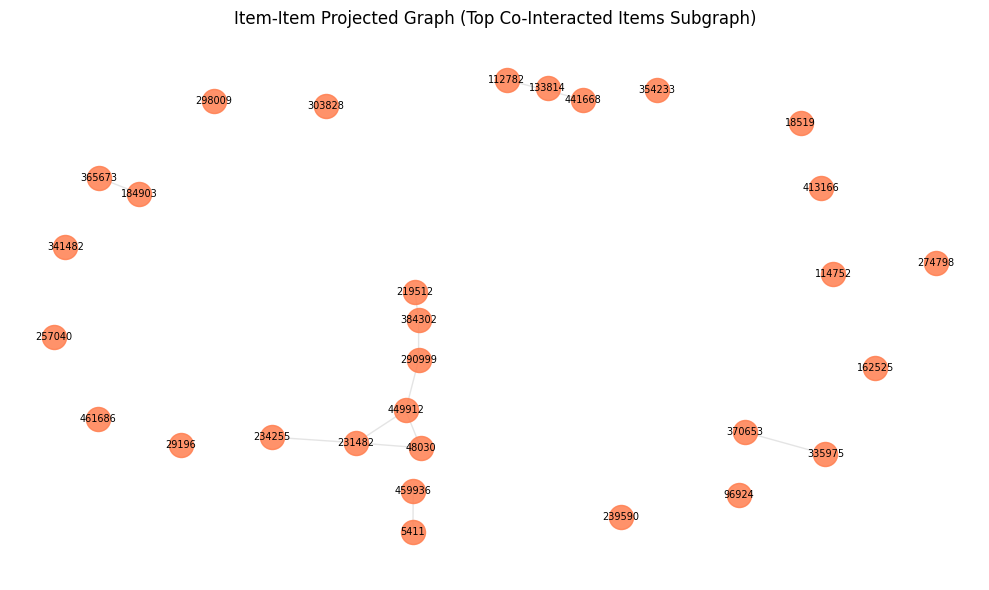

In [9]:
item_user_matrix = user_item_matrix.T.tocsr()
item_sparsity = 1.0 - (item_user_matrix.nnz / (item_user_matrix.shape[0] * item_user_matrix.shape[1]))

print("Item VSM Dimensions (Users):", item_user_matrix.shape[1])
print("Item VSM Matrix Shape (|I| x |U|):", item_user_matrix.shape)
print("Item VSM Matrix Sparsity:", f"{item_sparsity * 100:.4f}%")

top_active_items_idx = np.argsort(np.diff(item_user_matrix.indptr))[-30:]
sub_item_matrix = item_user_matrix[top_active_items_idx]
item_sim_sub = cosine_similarity(sub_item_matrix)
np.fill_diagonal(item_sim_sub, 0)

G_item = nx.Graph()
for i, it_idx in enumerate(top_active_items_idx):
    G_item.add_node(unique_items[it_idx])
    for j in range(i + 1, len(top_active_items_idx)):
        if item_sim_sub[i, j] > 0.05:
            G_item.add_edge(unique_items[it_idx], unique_items[top_active_items_idx[j]], weight=item_sim_sub[i, j])

plt.figure(figsize=(10, 6))
pos_it = nx.spring_layout(G_item, seed=42)
nx.draw_networkx_nodes(G_item, pos_it, node_color="coral", node_size=300, alpha=0.85)
nx.draw_networkx_edges(G_item, pos_it, edge_color="lightgray", alpha=0.6)
nx.draw_networkx_labels(G_item, pos_it, font_size=7)
plt.title("Item-Item Projected Graph (Top Co-Interacted Items Subgraph)")
plt.axis("off")
plt.tight_layout()
plt.savefig("item_vsm_graph.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
user_deg = np.diff(user_item_matrix.indptr)
item_deg = np.diff(item_user_matrix.indptr)

def graph_stats(G):
    return {
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "density": round(nx.density(G), 4),
        "isolated_nodes": nx.number_of_isolates(G),
        "connected_components": nx.number_connected_components(G),
    }

gs_u, gs_i = graph_stats(G_user), graph_stats(G_item)

df_projection_compare = pd.DataFrame({
    "User projection (U x I)": {
        "Vector dimension": user_item_matrix.shape[1],
        "Number of vectors": user_item_matrix.shape[0],
        "Full similarity matrix cells (n^2)": user_item_matrix.shape[0] ** 2,
        "Mean non-zeros per vector": round(user_deg.mean(), 3),
        "Median non-zeros per vector": float(np.median(user_deg)),
        "Max non-zeros per vector": int(user_deg.max()),
        "% vectors with exactly 1 non-zero": round((user_deg == 1).mean() * 100, 2),
        "Top-30 subgraph edges": gs_u["edges"],
        "Top-30 subgraph density": gs_u["density"],
        "Top-30 subgraph isolated nodes": gs_u["isolated_nodes"],
        "Top-30 subgraph components": gs_u["connected_components"],
    },
    "Item projection (I x U)": {
        "Vector dimension": item_user_matrix.shape[1],
        "Number of vectors": item_user_matrix.shape[0],
        "Full similarity matrix cells (n^2)": item_user_matrix.shape[0] ** 2,
        "Mean non-zeros per vector": round(item_deg.mean(), 3),
        "Median non-zeros per vector": float(np.median(item_deg)),
        "Max non-zeros per vector": int(item_deg.max()),
        "% vectors with exactly 1 non-zero": round((item_deg == 1).mean() * 100, 2),
        "Top-30 subgraph edges": gs_i["edges"],
        "Top-30 subgraph density": gs_i["density"],
        "Top-30 subgraph isolated nodes": gs_i["isolated_nodes"],
        "Top-30 subgraph components": gs_i["connected_components"],
    },
})

def fmt(x):
    return f"{x:,.0f}" if float(x).is_integer() else f"{x:,.4f}".rstrip("0")

df_projection_compare = df_projection_compare.apply(lambda col: col.map(fmt))

print("Non-zero entries (unique visitor-item pairs):", user_item_matrix.nnz)
print("Ratio |U|/|I|:", round(user_item_matrix.shape[0] / user_item_matrix.shape[1], 3))
print("Ratio |U|^2/|I|^2:", round((user_item_matrix.shape[0] / user_item_matrix.shape[1]) ** 2, 3))
display(df_projection_compare)
df_projection_compare.to_csv("projection_comparison.csv")

Non-zero entries (unique visitor-item pairs): 169747
Ratio |U|/|I|: 1.688
Ratio |U|^2/|I|^2: 2.851


,User projection (U x I),Item projection (I x U)
Vector dimension,"67,926","114,687"
Number of vectors,"114,687","67,926"
Full similarity matrix cells (n^2),"13,153,107,969","4,613,941,476"
Mean non-zeros per vector,1.48,2.499
Median non-zeros per vector,1,1
Max non-zeros per vector,507,113
% vectors with exactly 1 non-zero,81.85,58.53
Top-30 subgraph edges,52,11
Top-30 subgraph density,0.1195,0.0253
Top-30 subgraph isolated nodes,12,15


- Each item is a vector over users ($\mathbb{R}^{|U|}$) with the same weights.
- **Dimension:** 114,687. **Shape:** 67,926 x 114,687, the transpose of the user-item matrix, with the same 169,747 non-zeros and sparsity.
- The average item has 2.50 users, 58.53% have exactly one, and the most visited has 113.
- **Plot:** the 30 most popular items, linked when cosine > 0.05. It has 11 edges and 20 components: 15 isolated items and 5 small groups. Even popular items rarely share the same visitors. Again, this is a top-30 subgraph, not the whole graph.
- The next cell measures both projections at full size.

In [11]:
binary_ui = (user_item_matrix > 0).astype(np.int32).tocsr()
user_proj = (binary_ui @ binary_ui.T).tocsr()
item_proj = (binary_ui.T @ binary_ui).tocsr()

def projection_summary(P):
    n = P.shape[0]
    deg = np.diff(P.indptr) - 1
    edges = int(deg.sum() // 2)
    return {
        "Nodes": n,
        "Edges (shared-neighbour pairs)": edges,
        "Density": edges / (n * (n - 1) / 2),
        "Mean degree": deg.mean(),
        "Max degree": int(deg.max()),
        "% nodes with >= 1 neighbour": (deg > 0).mean() * 100,
        "Stored non-zeros (incl. diagonal)": int(P.nnz),
    }

df_projection_size = pd.DataFrame({
    "User-User projection": projection_summary(user_proj),
    "Item-Item projection": projection_summary(item_proj),
})

def fmt_size(x):
    return f"{x:,.0f}" if float(x).is_integer() else f"{x:.6g}"

display(df_projection_size.apply(lambda col: col.map(fmt_size)))
df_projection_size.to_csv("projection_size_full_graph.csv")

,User-User projection,Item-Item projection
Nodes,"114,687","67,926"
Edges (shared-neighbour pairs),"678,059","1,150,581"
Density,0.000103103,0.000498748
Mean degree,11.8245,33.8775
Max degree,"4,339","3,122"
% nodes with >= 1 neighbour,77.354,52.0964
Stored non-zeros (incl. diagonal),"1,470,805","2,369,088"


### Question 6: Which Projection Is Better?

The comparison uses the VSM statistics and the full projection sizes above.

1. **Dense size.** There are 114,687 users and 67,926 items. A full user-user similarity matrix has 1.32 x 10¹⁰ cells against 4.61 x 10⁹ for items, 2.85x larger.
2. **Real size.** Both projections are very sparse, and here the picture flips. The user-user projection has 678,059 edges (mean degree 11.8). The item-item projection has 1,150,581 (mean degree 33.9), about 1.7x more. A few very active users create this: one user with 507 items alone can link up to 128,271 item pairs, while the most visited item (113 users) links at most 6,328 user pairs. Both fit easily in memory (1.47M vs 2.37M stored entries), so efficiency does not separate them much.
3. **Coverage.** 77.4% of users have at least one neighbour against 52.1% of items. Almost half of the items have no neighbour, so the recommender needs a popularity fallback.
4. **Evidence per vector.** 81.85% of users have a single item, against 58.53% of items with a single user. A one-interaction profile is weak, while an item gathers behaviour from several visitors.
5. **Task fit.** We recommend items, so item-item neighbours give candidates directly.

**Conclusion:** item-item projection. The reason is effectiveness, not size: it models what we recommend and relies less on one-interaction user profiles. On efficiency it is a draw: smaller as a dense matrix, about 1.7x larger as a sparse graph. Capping very active users would shrink it.

### Question 7: Similarity on the Item Projection
Similarity is the cosine between item vectors. The full item-item projection has 1,150,581 pairs, so writing all of them would add about 2.3 million `SIMILAR_TO` relationships, over 10x the 214,725 interaction edges, and bury the graph. So it is computed only among the 100 most popular items. Pairs with score > 0.15 are written to Neo4j as `SIMILAR_TO {score}`, one per direction.

**7(b) Write similarities back to the graph**

```cypher
UNWIND $batch AS rel
MATCH (a:Item {itemId: rel.item1})
MATCH (b:Item {itemId: rel.item2})
MERGE (a)-[r1:SIMILAR_TO]->(b)
SET r1.score = rel.score
MERGE (b)-[r2:SIMILAR_TO]->(a)
SET r2.score = rel.score
```

`MERGE` plus `SET` is safe to re-run: scores get updated, not duplicated.

**7(a) Top 5 for a reference item**

```cypher
MATCH (target:Item {itemId: $ref_id})-[s:SIMILAR_TO]->(other:Item)
RETURN target.itemId AS reference_item, other.itemId AS similar_item, s.score AS similarity_score
ORDER BY s.score DESC
LIMIT 5
```

The reference item is the first item of the first pair above the threshold, so it is fixed for a given dataset. The result is in the next cell.

In [12]:
similarity_top_n = 100
similarity_threshold = 0.15

degrees = np.diff(item_user_matrix.indptr)
top_popular_item_indices = np.argsort(degrees)[-similarity_top_n:]
popular_item_matrix = item_user_matrix[top_popular_item_indices]
sim_matrix = cosine_similarity(popular_item_matrix)
np.fill_diagonal(sim_matrix, 0)

similarity_records = []
for i in range(len(top_popular_item_indices)):
    for j in range(i + 1, len(top_popular_item_indices)):
        score = float(sim_matrix[i, j])
        if score > similarity_threshold:
            similarity_records.append({
                "item1": int(unique_items[top_popular_item_indices[i]]),
                "item2": int(unique_items[top_popular_item_indices[j]]),
                "score": round(score, 4)
            })

write_sim_query = """
UNWIND $batch AS rel
MATCH (a:Item {itemId: rel.item1})
MATCH (b:Item {itemId: rel.item2})
MERGE (a)-[r1:SIMILAR_TO]->(b)
SET r1.score = rel.score
MERGE (b)-[r2:SIMILAR_TO]->(a)
SET r2.score = rel.score
"""

with driver.session(database="neo4j") as session:
    session.run(write_sim_query, batch=similarity_records)
    written = session.run("MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS c").single()["c"]

print(f"Items compared: {similarity_top_n} most popular | threshold: score > {similarity_threshold}")
print(f"Item pairs above threshold: {len(similarity_records)} | SIMILAR_TO relationships in graph: {written}")

reference_item_id = int(similarity_records[0]["item1"]) if len(similarity_records) > 0 else int(unique_items[top_popular_item_indices[-1]])

top5_sim_query = """
MATCH (target:Item {itemId: $ref_id})-[s:SIMILAR_TO]->(other:Item)
RETURN target.itemId AS reference_item, other.itemId AS similar_item, s.score AS similarity_score
ORDER BY s.score DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    res = session.run(top5_sim_query, ref_id=reference_item_id)
    df_top5 = pd.DataFrame([dict(r) for r in res])

print(f"Top 5 Similar Items for Reference Item {reference_item_id}:")
df_top5.to_csv("top5_similar_items.csv", index=False)
display(df_top5)

Items compared: 100 most popular | threshold: score > 0.15
Item pairs above threshold: 55 | SIMILAR_TO relationships in graph: 110
Top 5 Similar Items for Reference Item 454422:


,reference_item,similar_item,similarity_score
0,454422,166306,0.3953
1,454422,869,0.2976
2,454422,204494,0.2836
3,454422,44465,0.2787
4,454422,268081,0.2328


### Question 8: Before vs After Similarity

- **Before:** a bipartite graph with only `(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)`.
- **After:** the same graph plus `(:Item)-[:SIMILAR_TO {score}]->(:Item)` among popular items. Interaction edges are unchanged and only `SIMILAR_TO` is added (0 → 110).

Queries used: relationship counts by type, up to 3 sample visitors per item, and the similarity edges among the selected items.

```cypher
MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(r) AS relationship_count
ORDER BY relationship_count DESC
```

```cypher
MATCH (v:Visitor)-[r]->(i:Item)
WHERE i.itemId IN $items
WITH i, v, collect(DISTINCT type(r)) AS types
ORDER BY v.visitorId
WITH i, collect({visitor: v.visitorId, types: types})[..3] AS sample
UNWIND sample AS s
RETURN i.itemId AS item, s.visitor AS visitor, s.types AS interactions
```

```cypher
MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
WHERE a.itemId IN $items AND b.itemId IN $items AND a.itemId < b.itemId
RETURN a.itemId AS item1, b.itemId AS item2, s.score AS similarity
ORDER BY similarity DESC
```

The plot shows the reference item (gold), its 5 neighbours (red) and up to 3 visitors per item (blue), with the same layout in both panels. The left panel has interactions only. The right panel adds the green `SIMILAR_TO` edges with their scores, including edges between the neighbours themselves.

,relationship_type,before_similarity,after_similarity
0,VIEWED,207368,207368
1,ADDED_TO_CART,5520,5520
2,BOUGHT,1837,1837
3,SIMILAR_TO,0,110


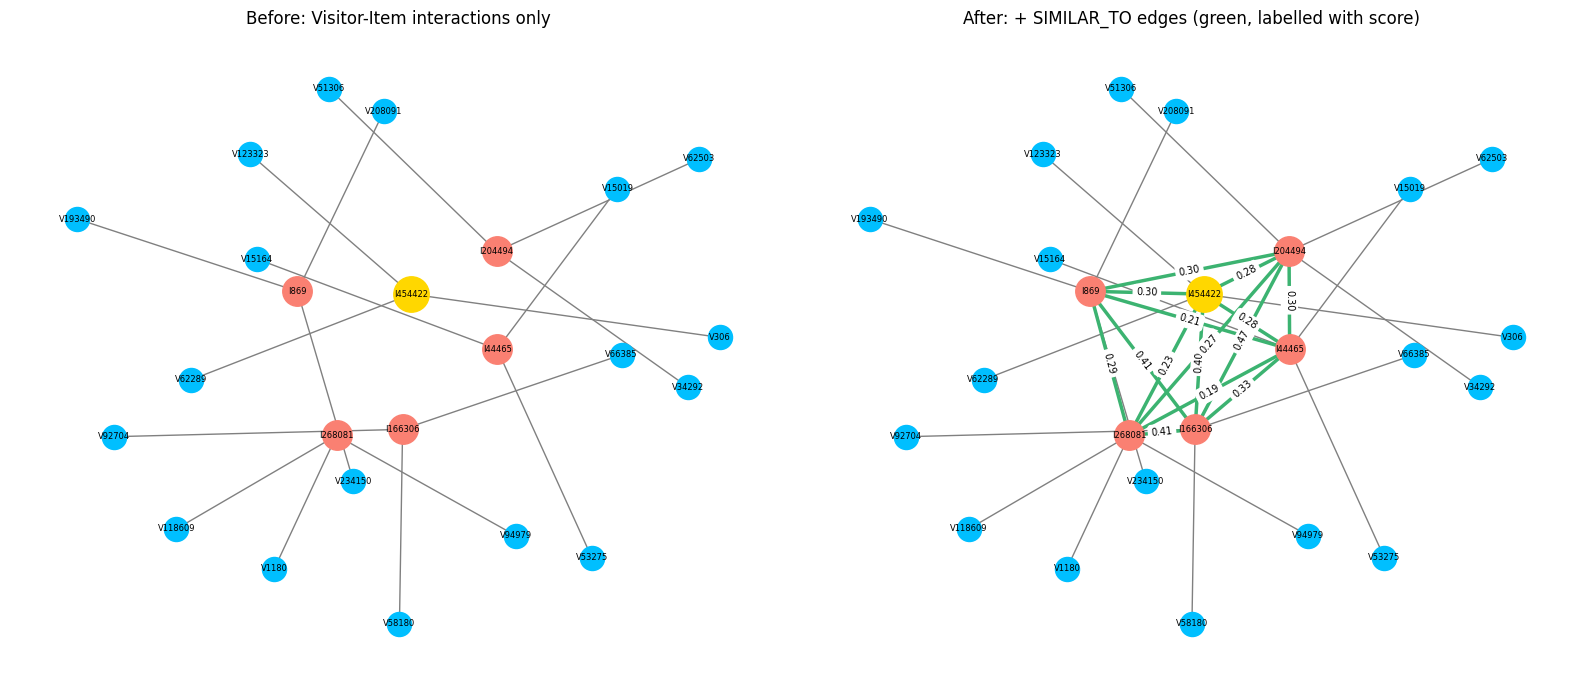

In [13]:
rel_count_query = "MATCH ()-[r]->() RETURN type(r) AS relationship_type, count(r) AS relationship_count ORDER BY relationship_count DESC"

with driver.session(database="neo4j") as session:
    df_rels_after = pd.DataFrame([dict(r) for r in session.run(rel_count_query)])

df_rel_compare = (
    df_rels.rename(columns={"relationship_count": "before_similarity"})
    .merge(df_rels_after.rename(columns={"relationship_count": "after_similarity"}), on="relationship_type", how="outer")
    .fillna(0)
)
df_rel_compare[["before_similarity", "after_similarity"]] = df_rel_compare[["before_similarity", "after_similarity"]].astype(int)
df_rel_compare = df_rel_compare.sort_values("after_similarity", ascending=False).reset_index(drop=True)
display(df_rel_compare)
df_rel_compare.to_csv("relationship_composition_before_after.csv", index=False)

focus_items = [reference_item_id] + df_top5["similar_item"].astype(int).tolist()

sample_query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE i.itemId IN $items
WITH i, v, collect(DISTINCT type(r)) AS types
ORDER BY v.visitorId
WITH i, collect({visitor: v.visitorId, types: types})[..3] AS sample
UNWIND sample AS s
RETURN i.itemId AS item, s.visitor AS visitor, s.types AS interactions
"""

sim_edge_query = """
MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
WHERE a.itemId IN $items AND b.itemId IN $items AND a.itemId < b.itemId
RETURN a.itemId AS item1, b.itemId AS item2, s.score AS similarity
ORDER BY similarity DESC
"""

with driver.session(database="neo4j") as session:
    sample_rows = [dict(r) for r in session.run(sample_query, items=focus_items)]
    sim_rows = [dict(r) for r in session.run(sim_edge_query, items=focus_items)]

G_before = nx.Graph()
for item_id in focus_items:
    G_before.add_node(f"I{item_id}")
for row in sample_rows:
    G_before.add_edge(f"V{row['visitor']}", f"I{row['item']}")

G_after = G_before.copy()
for row in sim_rows:
    G_after.add_edge(f"I{row['item1']}", f"I{row['item2']}", weight=row["similarity"])

pos = nx.spring_layout(G_after, seed=42, k=0.9)
ref_node = f"I{reference_item_id}"

def draw_panel(ax, G, title):
    visitor_nodes = [n for n in G.nodes() if n.startswith("V")]
    item_nodes = [n for n in G.nodes() if n.startswith("I") and n != ref_node]
    interaction_edges = [(u, v) for u, v in G.edges() if u.startswith("V") or v.startswith("V")]
    similarity_edges = [(u, v) for u, v in G.edges() if u.startswith("I") and v.startswith("I")]
    nx.draw_networkx_nodes(G, pos, nodelist=visitor_nodes, node_color="deepskyblue", node_size=300, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="salmon", node_size=450, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[ref_node], node_color="gold", node_size=650, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=interaction_edges, edge_color="gray", ax=ax)
    if similarity_edges:
        nx.draw_networkx_edges(G, pos, edgelist=similarity_edges, edge_color="mediumseagreen", width=2.5, ax=ax)
        nx.draw_networkx_edge_labels(
            G, pos,
            edge_labels={(u, v): f"{G[u][v]['weight']:.2f}" for u, v in similarity_edges},
            font_size=7, ax=ax
        )
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_panel(axes[0], G_before, "Before: Visitor-Item interactions only")
draw_panel(axes[1], G_after, "After: + SIMILAR_TO edges (green, labelled with score)")
plt.tight_layout()
plt.savefig("graph_topology_before_after.png", dpi=300, bbox_inches="tight")
plt.show()

## 2.2 Analytics

### Question 1: Random User Selection
A user is eligible if they appear in both P1 and P2 (4,564 users), have at least 2 items in P1, and have at least one ground-truth item. Ground truth means items seen in P2 that exist in the P1 catalogue and were not in the user's P1 history. Items already seen are excluded because the recommender never re-suggests them, and items missing from P1 have no vector. 1,064 users qualify.

The sorted list is sampled with `np.random.RandomState(42).choice`, so the pick is reproducible.

In [14]:
catalog_p1 = set(df_p1["itemid"].unique().tolist())
p1_items_by_user = df_p1.groupby("visitorid")["itemid"].apply(set)
p2_items_by_user = df_p2.groupby("visitorid")["itemid"].apply(set)

returning_users = sorted(set(p1_items_by_user.index) & set(p2_items_by_user.index))

eligible_users = []
for uid in returning_users:
    history = p1_items_by_user[uid]
    truth = (p2_items_by_user[uid] & catalog_p1) - history
    if len(history) >= 2 and len(truth) >= 1:
        eligible_users.append(uid)

rng = np.random.RandomState(42)
selected_user_id = int(rng.choice(eligible_users))

p1_user_items = sorted(int(i) for i in p1_items_by_user[selected_user_id])
p2_user_all_items = sorted(int(i) for i in p2_items_by_user[selected_user_id])
p2_user_ground_truth = sorted(int(i) for i in (p2_items_by_user[selected_user_id] & catalog_p1) - p1_items_by_user[selected_user_id])

print(f"Users in both P1 and P2: {len(returning_users)}")
print(f"Eligible users (>= 2 items in P1 and >= 1 new catalog item in P2): {len(eligible_users)}")
print(f"Randomly Selected User ID (seed=42): {selected_user_id}")
print(f"P1 Interacted Items (Training History): {p1_user_items}")
print(f"P2 Interacted Items (all): {p2_user_all_items}")
print(f"P2 Ground Truth (new items, in P1 catalog, not in P1 history): {p2_user_ground_truth}")

Users in both P1 and P2: 4564
Eligible users (>= 2 items in P1 and >= 1 new catalog item in P2): 1064
Randomly Selected User ID (seed=42): 1145341
P1 Interacted Items (Training History): [175574, 303517]
P2 Interacted Items (all): [363740]
P2 Ground Truth (new items, in P1 catalog, not in P1 history): [363740]


### Question 1(a): Item-based KNN
For each item in the user's history:
1. Compute cosine similarity to all items.
2. Mask the item itself and everything the user already has, then keep the 5 nearest neighbours ($k = 5$).
3. Add each neighbour's similarity x the history item's weight to its score.

Candidates are ranked by score, with ties broken by popularity and then item id. If fewer than 5 candidates exist, the list is filled with the most popular unseen items, labelled `Popularity fallback`.

In [15]:
def recommend_knn_items(user_id, k=5, top_n=5):
    user_row = user_item_matrix[user_to_idx[user_id]]
    history_idx = user_row.indices
    history_weights = user_row.data
    item_popularity = np.diff(item_user_matrix.indptr)
    seen_mask = np.zeros(len(unique_items), dtype=bool)
    seen_mask[history_idx] = True

    candidate_scores = {}
    for h_idx, weight in zip(history_idx, history_weights):
        sims = np.round(cosine_similarity(item_user_matrix[h_idx], item_user_matrix).ravel(), 6)
        sims[seen_mask] = -1.0
        neighbor_order = np.lexsort((unique_items, -item_popularity, -sims))[:k]
        for n_idx in neighbor_order:
            if sims[n_idx] > 0:
                candidate_scores[n_idx] = candidate_scores.get(n_idx, 0.0) + sims[n_idx] * weight

    ranked = sorted(candidate_scores.items(), key=lambda kv: (-kv[1], -item_popularity[kv[0]], unique_items[kv[0]]))
    recs = [(int(unique_items[idx]), float(score), "KNN") for idx, score in ranked[:top_n]]

    if len(recs) < top_n:
        chosen = {r[0] for r in recs}
        for idx in np.lexsort((unique_items, -item_popularity)):
            if seen_mask[idx] or int(unique_items[idx]) in chosen:
                continue
            recs.append((int(unique_items[idx]), 0.0, "Popularity fallback"))
            chosen.add(int(unique_items[idx]))
            if len(recs) == top_n:
                break
    return recs

knn_recommendations = recommend_knn_items(selected_user_id, k=5, top_n=5)
df_recs = pd.DataFrame(knn_recommendations, columns=["ItemID", "PredictedScore", "Source"])
df_recs.insert(0, "Rank", range(1, len(df_recs) + 1))
display(df_recs)

,Rank,ItemID,PredictedScore,Source
0,1,166122,0.374166,KNN
1,2,393956,0.267261,KNN
2,3,175668,0.174964,KNN
3,4,345059,0.154303,KNN
4,5,101718,0.124838,KNN


### Question 1(b): Top 3 Items to Advertise
For $k = 5$ the model returns 5 recommendations. The first three are advertised, and all five are kept for Hit@5 and NDCG@5.

In [16]:
top_3_advertised = df_recs.head(3)
print(f"Top 3 Items Advertised for User {selected_user_id} (k=5):")
for _, row in top_3_advertised.iterrows():
    print(f"Rank {int(row['Rank'])}: Item ID {int(row['ItemID'])} (Score: {row['PredictedScore']:.4f}, Source: {row['Source']})")
df_recs.to_csv("knn_recommendations.csv", index=False)

Top 3 Items Advertised for User 1145341 (k=5):
Rank 1: Item ID 166122 (Score: 0.3742, Source: KNN)
Rank 2: Item ID 393956 (Score: 0.2673, Source: KNN)
Rank 3: Item ID 175668 (Score: 0.1750, Source: KNN)


### Question 2(a): Hit@5
Equals 1 if at least one of the 5 recommended items is in the user's ground truth, otherwise 0.

In [17]:
top_5_recommended_items = df_recs["ItemID"].tolist()[:5]
ground_truth_set = set(p2_user_ground_truth)

hit_items = [item for item in top_5_recommended_items if item in ground_truth_set]
hit_at_5 = 1 if len(hit_items) > 0 else 0

print(f"Top-5 recommended items: {top_5_recommended_items}")
print(f"Ground truth (P2 new items): {sorted(ground_truth_set)}")
print(f"Matched items: {hit_items}")
print(f"Hit@5 Result: {hit_at_5}")

Top-5 recommended items: [166122, 393956, 175668, 345059, 101718]
Ground truth (P2 new items): [363740]
Matched items: []
Hit@5 Result: 0


### Question 2(b): NDCG@5
Rewards relevant items that are ranked higher. Relevance is 1 if the item is in the ground truth, otherwise 0.

- $DCG@5 = \sum_{r=1}^{5} \frac{2^{rel_r}-1}{\log_2(r+1)}$
- $IDCG@5$ is the DCG if all $\min(|GT|, 5)$ ground-truth items were ranked first
- $NDCG@5 = DCG@5 / IDCG@5$, between 0 and 1

With one relevant item, a hit at rank $r$ scores $1/\log_2(r+1)$.

In [18]:
k_eval = 5
relevance = [1 if item in ground_truth_set else 0 for item in top_5_recommended_items]
relevance += [0] * (k_eval - len(relevance))

dcg_at_5 = sum((2**rel - 1) / np.log2(rank + 1) for rank, rel in enumerate(relevance, start=1))

ideal_relevance = [1] * min(len(ground_truth_set), k_eval)
ideal_relevance += [0] * (k_eval - len(ideal_relevance))
idcg_at_5 = sum((2**rel - 1) / np.log2(rank + 1) for rank, rel in enumerate(ideal_relevance, start=1))

ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

eval_df = pd.DataFrame({
    "Rank": range(1, k_eval + 1),
    "Recommended_ItemID": top_5_recommended_items,
    "In_P2_GroundTruth": relevance,
    "Discount": [1.0 / np.log2(r + 1) for r in range(1, k_eval + 1)],
    "Ideal_Relevance": ideal_relevance
})

print("NDCG@5 Evaluation:")
display(eval_df)
print(f"DCG@5:  {dcg_at_5:.4f}")
print(f"IDCG@5: {idcg_at_5:.4f}")
print(f"NDCG@5: {ndcg_at_5:.4f}")
eval_df.to_csv("ndcg_evaluation_table.csv", index=False)

NDCG@5 Evaluation:


,Rank,Recommended_ItemID,In_P2_GroundTruth,Discount,Ideal_Relevance
0,1,166122,0,1.000000,1
1,2,393956,0,0.630930,0
2,3,175668,0,0.500000,0
3,4,345059,0,0.430677,0
4,5,101718,0,0.386853,0


DCG@5:  0.0000
IDCG@5: 1.0000
NDCG@5: 0.0000


### Result for the Selected User
User 1145341 (seed 42) had items 175574 and 303517 in P1 and one ground-truth item in P2: 363740. The top-5 KNN list (166122, 393956, 175668, 345059, 101718) does not contain it, so **Hit@5 = 0** and **NDCG@5 = 0**.

One user with one relevant item is a very noisy test. With a two-item history (81.85% of users have just one item), the model has little to work with. The supplementary evaluation below averages over many users.

### Supplementary: Evaluation over 200 Users
The same metrics averaged over 200 eligible users (seed 42) and compared with a popularity baseline.

In [19]:
eval_rng = np.random.RandomState(42)
eval_users = eval_rng.choice(eligible_users, size=min(200, len(eligible_users)), replace=False)

item_popularity_all = np.diff(item_user_matrix.indptr)
popularity_order = np.lexsort((unique_items, -item_popularity_all))

def popularity_recs(history_items, top_n=5):
    out = []
    for idx in popularity_order:
        item = int(unique_items[idx])
        if item in history_items:
            continue
        out.append(item)
        if len(out) == top_n:
            break
    return out

def hit_and_ndcg(recs, truth, k=5):
    rel = [1 if r in truth else 0 for r in recs[:k]]
    rel += [0] * (k - len(rel))
    dcg = sum(r / np.log2(i + 1) for i, r in enumerate(rel, start=1))
    ideal = [1] * min(len(truth), k) + [0] * (k - min(len(truth), k))
    idcg = sum(r / np.log2(i + 1) for i, r in enumerate(ideal, start=1))
    return int(sum(rel) > 0), (dcg / idcg if idcg > 0 else 0.0)

rows = []
for uid in eval_users:
    uid = int(uid)
    history = p1_items_by_user[uid]
    truth = (p2_items_by_user[uid] & catalog_p1) - history
    knn_items = [r[0] for r in recommend_knn_items(uid, k=5, top_n=5)]
    pop_items = popularity_recs(history)
    knn_hit, knn_ndcg = hit_and_ndcg(knn_items, truth)
    pop_hit, pop_ndcg = hit_and_ndcg(pop_items, truth)
    rows.append({"user": uid, "knn_hit5": knn_hit, "knn_ndcg5": knn_ndcg, "pop_hit5": pop_hit, "pop_ndcg5": pop_ndcg})

df_eval_agg = pd.DataFrame(rows)
summary_agg = pd.DataFrame({
    "Model": ["Item-based KNN (k=5)", "Popularity baseline"],
    "Users evaluated": [len(df_eval_agg)] * 2,
    "Mean Hit@5": [df_eval_agg["knn_hit5"].mean(), df_eval_agg["pop_hit5"].mean()],
    "Mean NDCG@5": [df_eval_agg["knn_ndcg5"].mean(), df_eval_agg["pop_ndcg5"].mean()],
})
display(summary_agg.round(4))
summary_agg.to_csv("aggregate_evaluation_summary.csv", index=False)

,Model,Users evaluated,Mean Hit@5,Mean NDCG@5
0,Item-based KNN (k=5),200,0.05,0.0212
1,Popularity baseline,200,0.00,0.0000


KNN gets Hit@5 = 0.05 and NDCG@5 = 0.0212, while the popularity baseline gets 0 on both. The numbers are low because histories are short and each user has only a few relevant items among about 68k. With 200 users (10 hits) the sample is small, but it shows KNN picks up some signal. (This is extra context)

## Outputs Archive

In [20]:
zip_output_name = "uts_gds_outputs.zip"

files_to_pack = [
    "events_p1_train.csv",
    "events_p2_test.csv",
    "events_filtered_p1_p2.csv",
    "summary_stats_p1_p2.csv",
    "subgraph_nodes_composition.csv",
    "subgraph_relationships_composition.csv",
    "user_vsm_graph.png",
    "item_vsm_graph.png",
    "projection_comparison.csv",
    "projection_size_full_graph.csv",
    "top5_similar_items.csv",
    "relationship_composition_before_after.csv",
    "graph_topology_before_after.png",
    "knn_recommendations.csv",
    "ndcg_evaluation_table.csv",
    "aggregate_evaluation_summary.csv"
]

with zipfile.ZipFile(zip_output_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_name in files_to_pack:
        if os.path.exists(file_name):
            zipf.write(file_name, arcname=file_name)

print("Packaged files in archive:")
for file_name in files_to_pack:
    if os.path.exists(file_name):
        print(f" - {file_name}")

if IN_COLAB:
    from google.colab import files
    print("Triggering automatic download in Google Colab...")
    files.download(zip_output_name)
else:
    print(f"Archive successfully generated at: {os.path.abspath(zip_output_name)}")

Packaged files in archive:
 - events_p1_train.csv
 - events_p2_test.csv
 - events_filtered_p1_p2.csv
 - summary_stats_p1_p2.csv
 - subgraph_nodes_composition.csv
 - subgraph_relationships_composition.csv
 - user_vsm_graph.png
 - item_vsm_graph.png
 - projection_comparison.csv
 - projection_size_full_graph.csv
 - top5_similar_items.csv
 - relationship_composition_before_after.csv
 - graph_topology_before_after.png
 - knn_recommendations.csv
 - ndcg_evaluation_table.csv
 - aggregate_evaluation_summary.csv
Triggering automatic download in Google Colab...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>